# JASON pivot features — an illustrated tour

**JASON** turns a trailing OHLC window into a set of *pivot-based deviation*
features. For each bar it locates the running high/low **pivots**, frequency-weights
the dominant ones, estimates volatility, and measures how far price sits from each
pivot in **σ·√t units** (`high_z`, `low_z`). It also projects vol-adjusted
support/resistance bands (`*_json2`).

This notebook uses the consolidated engine in `src/signals/jason.py`, which holds
two implementations that emit the **same 15-column contract**:

| Function | Role |
|---|---|
| `compute_jason_vectorized` | numba production calculator (gap-adjusted QV + tanh fresh-pivot vol blend) |
| `compute_jason_vectorized_cs` | faithful C# `JSONStudy` reference port (golden truth for parity checks) |

Data: **Binance BTCUSDT perpetual, 1h bars**, read through the single lake read
path (`src.data.query.get`).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.edgecolor": "#888",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

from src.data.query import get
from src.signals.jason import compute_jason_vectorized, compute_jason_vectorized_cs

SYMBOL, TF = "btcusdt", "1h"
START, END = "2022-06-01", "2024-06-01"

ohlc = get("perps", "binance", SYMBOL, "bars", TF, start=START, end=END)
print(f"{SYMBOL} {TF}: {ohlc.shape[0]:,} bars  {ohlc.index[0]} -> {ohlc.index[-1]}")
ohlc.head(3)

btcusdt 1h: 17,545 bars  2022-06-01 00:00:00 -> 2024-06-01 00:00:00


,open,high,low,close,volume
ts,,,,,
2022-06-01 00:00:00,31797.9,31986.1,31680.0,31925.5,13588.888
2022-06-01 01:00:00,31925.5,31938.6,31825.7,31914.9,5821.940
2022-06-01 02:00:00,31914.9,31915.0,31710.0,31794.1,9097.811


## The 15 features

`lookback=7` days, `n_pivots=5`. All produced per bar from the trailing window
ending at that bar (strictly causal).

| Column | Meaning |
|---|---|
| `high_z` / `low_z` | distance **up to** the dominant high pivot / **up from** the dominant low pivot, in σ·√t |
| `high_pivot` / `low_pivot` | vol-weighted dominant pivot price (resistance / support) |
| `high_vol` / `low_vol` | annualized vol at the pivot (×100) |
| `high_days` / `low_days` | age of the pivot, in days |
| `*_json2` | vol-adjusted S/R projection at the horizon (`pivot·exp(∓2σ√t)`) |
| `*_json2_plus_1d` / `_plus_2d` | same projection 1 / 2 days further out |
| `last_fx` | the current close (reference) |

A natural contrarian **s-score** is `low_z − high_z`: **>0 rich** (near resistance,
far above support → fade short), **<0 cheap** (→ fade long).

In [2]:
feat = compute_jason_vectorized(ohlc.copy(), SYMBOL.upper(), TF,
                                lookback=7, n_pivots=5, min_days=1)
feat["sscore"] = feat["low_z"] - feat["high_z"]
close = ohlc["close"].reindex(feat.index)
print("features:", feat.shape)
feat[["high_z", "low_z", "high_pivot", "low_pivot", "high_vol",
      "high_days", "high_json2", "low_json2", "sscore"]].tail(4)

Computing JASON for BTCUSDT:   0%|          | 0/17377 [00:00<?, ?it/s]

Computing JASON for BTCUSDT:   0%|          | 1/17377 [00:05<24:57:19,  5.17s/it]

Computing JASON for BTCUSDT:  27%|██▋       | 4654/17377 [00:05<00:10, 1251.25it/s]

Computing JASON for BTCUSDT:  54%|█████▎    | 9313/17377 [00:05<00:02, 2928.30it/s]

Computing JASON for BTCUSDT:  80%|███████▉  | 13846/17377 [00:05<00:00, 5056.40it/s]

features: (17377, 16)


,high_z,low_z,high_pivot,low_pivot,high_vol,high_days,high_json2,low_json2,sscore
2024-05-31 21:00:00,1.10,0.61,70142.486331,66700.5,41.46,2.8,65412.872729,69708.220645,-0.49
2024-05-31 22:00:00,1.13,0.58,70130.471942,66700.5,41.05,2.8,65421.201967,69654.445801,-0.55
2024-05-31 23:00:00,1.10,0.61,70118.457554,66700.5,40.93,2.8,65404.952506,69641.952329,-0.49
2024-06-01 00:00:00,1.05,0.70,70106.443165,66700.5,40.55,2.8,65414.278319,69586.469299,-0.35


## 1 — Price, dominant pivots & JSON2 bands

The blended `high_pivot` / `low_pivot` track dynamic resistance/support; the
`high_json2` / `low_json2` bands are the vol-adjusted projections price is expected
to reach off each pivot. Zoomed to the most recent ~4 months for legibility.

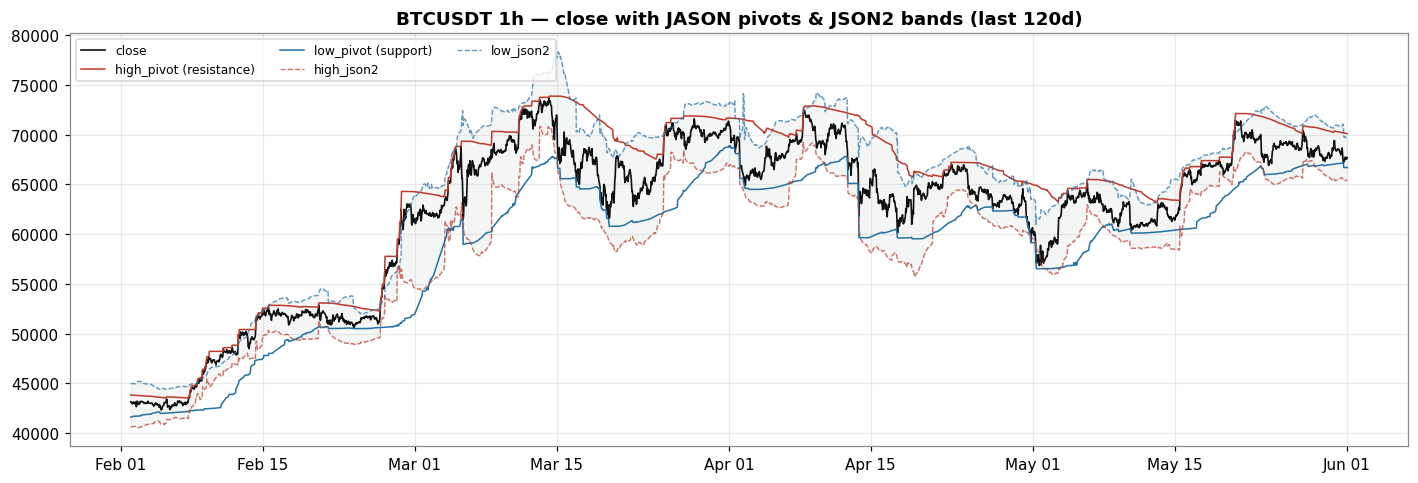

In [3]:
zoom = feat.index >= (feat.index[-1] - pd.Timedelta(days=120))
z = feat[zoom]
c = close[zoom]

fig, ax = plt.subplots()
ax.plot(c.index, c.values, color="#111", lw=1.1, label="close")
ax.plot(z.index, z["high_pivot"], color="#c0392b", lw=1.0, label="high_pivot (resistance)")
ax.plot(z.index, z["low_pivot"],  color="#2471a3", lw=1.0, label="low_pivot (support)")
ax.plot(z.index, z["high_json2"], color="#c0392b", lw=0.9, ls="--", alpha=0.7, label="high_json2")
ax.plot(z.index, z["low_json2"],  color="#2471a3", lw=0.9, ls="--", alpha=0.7, label="low_json2")
ax.fill_between(z.index, z["low_json2"], z["high_json2"], color="#95a5a6", alpha=0.10)
ax.set_title("BTCUSDT 1h — close with JASON pivots & JSON2 bands (last 120d)")
ax.legend(ncol=3, loc="upper left", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout(); plt.show()

## 2 — Deviation z-scores and the contrarian s-score

`high_z` rises as price nears resistance; `low_z` rises as price pulls away from
support. The composite `sscore = low_z − high_z` is positive when price is *rich*
and negative when *cheap*.

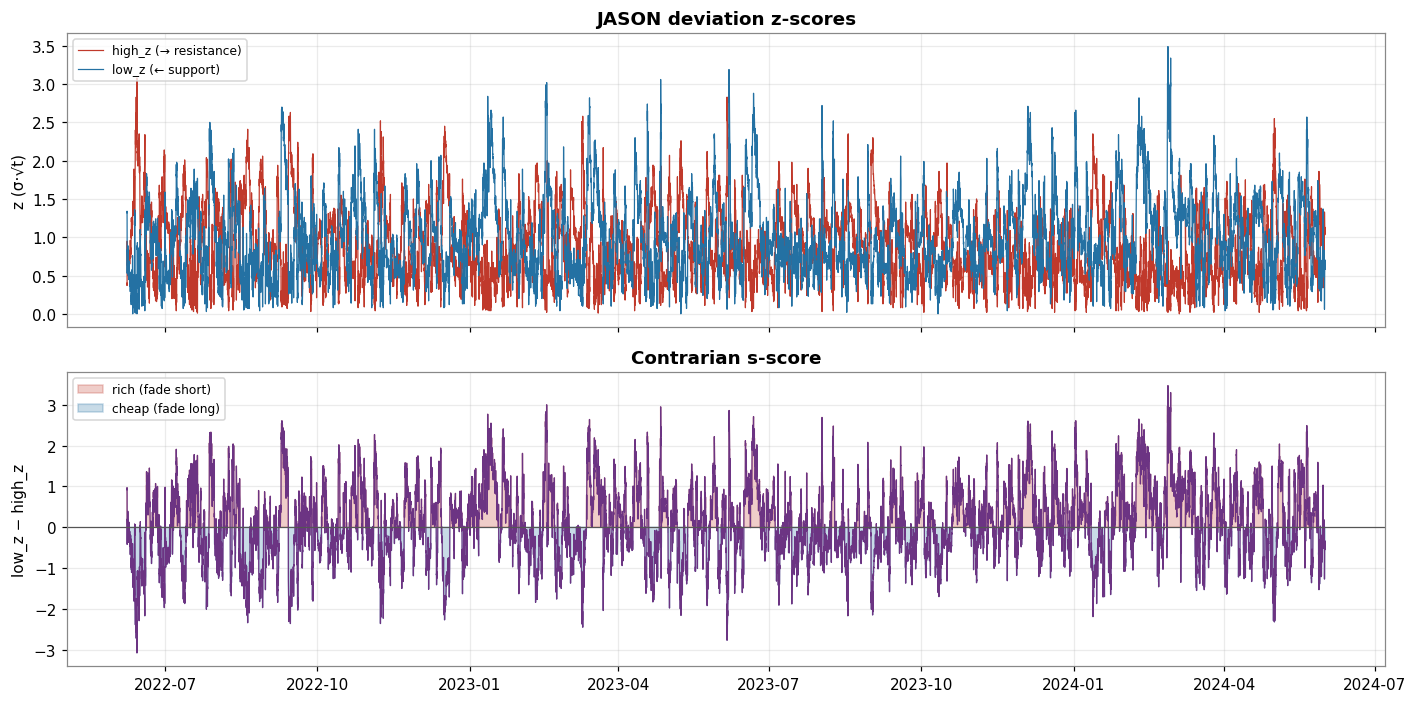

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

ax1.plot(feat.index, feat["high_z"], color="#c0392b", lw=0.8, label="high_z (→ resistance)")
ax1.plot(feat.index, feat["low_z"],  color="#2471a3", lw=0.8, label="low_z (← support)")
ax1.set_ylabel("z (σ·√t)"); ax1.legend(loc="upper left", fontsize=8)
ax1.set_title("JASON deviation z-scores")

ax2.plot(feat.index, feat["sscore"], color="#6c3483", lw=0.8)
ax2.axhline(0, color="#555", lw=0.8)
ax2.fill_between(feat.index, feat["sscore"], 0, where=feat["sscore"] > 0,
                 color="#c0392b", alpha=0.25, label="rich (fade short)")
ax2.fill_between(feat.index, feat["sscore"], 0, where=feat["sscore"] < 0,
                 color="#2471a3", alpha=0.25, label="cheap (fade long)")
ax2.set_ylabel("low_z − high_z"); ax2.legend(loc="upper left", fontsize=8)
ax2.set_title("Contrarian s-score")
plt.tight_layout(); plt.show()

## 3 — Pivot volatility and age

`high_vol` / `low_vol` are the annualized vol (×100) attached to each dominant
pivot; `high_days` / `low_days` are how long ago that pivot formed.

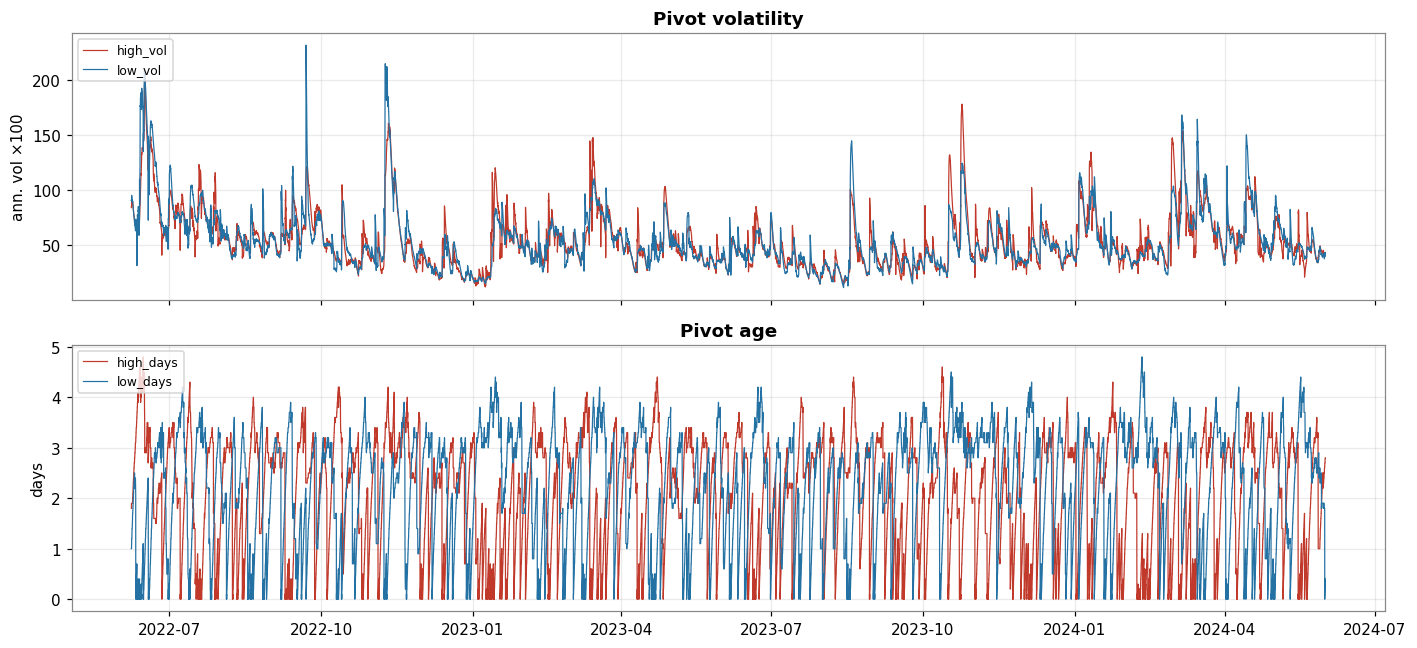

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax1.plot(feat.index, feat["high_vol"], color="#c0392b", lw=0.8, label="high_vol")
ax1.plot(feat.index, feat["low_vol"],  color="#2471a3", lw=0.8, label="low_vol")
ax1.set_ylabel("ann. vol ×100"); ax1.legend(loc="upper left", fontsize=8)
ax1.set_title("Pivot volatility")

ax2.plot(feat.index, feat["high_days"], color="#c0392b", lw=0.8, label="high_days")
ax2.plot(feat.index, feat["low_days"],  color="#2471a3", lw=0.8, label="low_days")
ax2.set_ylabel("days"); ax2.legend(loc="upper left", fontsize=8)
ax2.set_title("Pivot age")
plt.tight_layout(); plt.show()

## 4 — Parity: numba production vs C# reference port

Both run on identical inputs and windows, so any gap is **pure logic**. With the
prod-accurate config (`pivot_method="classic"`, `hist_vol="OCHL"`, `λ=0`) the C#
port matches the true C# golden to ≤1.5e-11 — it is *the* reference.

- **Pivot levels agree** on ~95% of bars exactly; the residual are the documented
  top-N **vote-tie-break** ordering difference (numba `argsort` vs the port's
  stable insertion order) when several pivots share a vote count.
- **`z` diverges by design**: the numba impl adds an overnight/weekend **gap
  term** to QV and a **tanh fresh-pivot vol blend**, so its per-pivot vol — and
  thus the vol-scaled `z` — differs from the port's single-window OCHL vol.

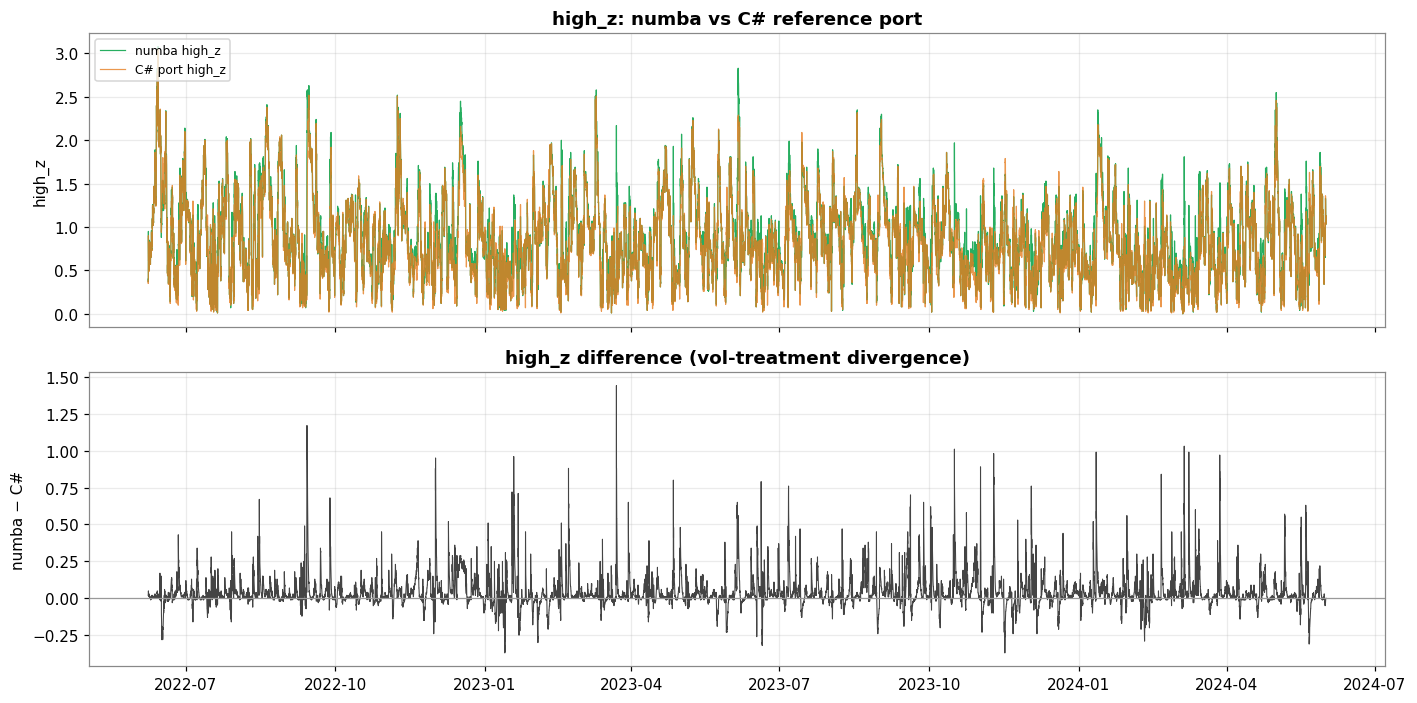

bars compared: 17,377
high_pivot  exact-match: 94.5%   max rel|diff|: 3.88%  (top-N tie-break)
high_z      mean|diff|: 0.064   max|diff|: 1.440  (intended vol divergence)


In [6]:
feat_cs = compute_jason_vectorized_cs(ohlc.copy(), SYMBOL.upper(), TF,
                                      lookback=7, n_pivots=5, min_days=1,
                                      pivot_method="classic", hist_vol="OCHL")
common = feat.index.intersection(feat_cs.index)
diff_z = (feat.loc[common, "high_z"] - feat_cs.loc[common, "high_z"])
diff_piv = (feat.loc[common, "high_pivot"] - feat_cs.loc[common, "high_pivot"]).abs()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ax1.plot(common, feat.loc[common, "high_z"], color="#27ae60", lw=0.8, label="numba high_z")
ax1.plot(common, feat_cs.loc[common, "high_z"], color="#e67e22", lw=0.8, alpha=0.8, label="C# port high_z")
ax1.set_ylabel("high_z"); ax1.legend(loc="upper left", fontsize=8)
ax1.set_title("high_z: numba vs C# reference port")

ax2.plot(common, diff_z, color="#444", lw=0.7)
ax2.axhline(0, color="#999", lw=0.8)
ax2.set_ylabel("numba − C#"); ax2.set_title("high_z difference (vol-treatment divergence)")
plt.tight_layout(); plt.show()

rel_piv = diff_piv / feat_cs.loc[common, "high_pivot"].abs()
print(f"bars compared: {len(common):,}")
print(f"high_pivot  exact-match: {(rel_piv < 1e-9).mean():.1%}   max rel|diff|: {rel_piv.max():.2%}  (top-N tie-break)")
print(f"high_z      mean|diff|: {diff_z.abs().mean():.3f}   max|diff|: {diff_z.abs().max():.3f}  (intended vol divergence)")

## 5 — Latest snapshot

The most recent bar's full feature vector and its read.

In [7]:
last = feat.iloc[-1]
px = float(close.iloc[-1])
print(f"as of {feat.index[-1]}   close = {px:,.1f}\n")
print(last.to_frame("value").to_string())

s = last["sscore"]
verdict = "RICH — near resistance, fade short" if s > 0 else "CHEAP — near support, fade long"
print(f"\ns-score (low_z - high_z) = {s:+.2f}  ->  {verdict}")
print(f"resistance high_pivot={last['high_pivot']:,.0f} ({last['high_days']:.1f}d old), "
      f"support low_pivot={last['low_pivot']:,.0f} ({last['low_days']:.1f}d old)")

as of 2024-06-01 00:00:00   close = 67,690.0

                           value
high_vol               40.550000
high_days               2.800000
high_z                  1.050000
high_pivot          70106.443165
high_json2          65414.278319
high_json2_plus_1d  64588.079159
high_json2_plus_2d  63901.393961
last_fx             67690.000000
low_json2           69586.469299
low_json2_plus_1d   70818.146376
low_json2_plus_2d   71778.007360
low_pivot           66700.500000
low_z                   0.700000
low_days                0.400000
low_vol                40.460000
sscore                 -0.350000

s-score (low_z - high_z) = -0.35  ->  CHEAP — near support, fade long
resistance high_pivot=70,106 (2.8d old), support low_pivot=66,700 (0.4d old)
